# A atenção do Transformer treinado

O bigrama e o trigrama só enxergam 1 ou 2 tokens para trás: a nota pedida sai da visão deles logo na
primeira palavra. O Transformer (`src/nano_review/models/transformer.py`) tem a **atenção**: em cada
posição, cada cabeça distribui um peso entre **todas** as posições anteriores, e a saída é a média
ponderada do que elas carregam.

Este notebook abre o modelo do primeiro treino (`models/transformer.pt`, gerado pelo `dvc repro`) e
responde a três perguntas:

1. Como são os mapas de atenção numa resenha?
2. Alguma cabeça olha para o token `<nota_k>` mesmo longe do começo?
3. Trocar a nota muda a previsão várias palavras depois? Isso é o que o trigrama não consegue.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap
from tokenizers import Tokenizer

from nano_review.data.dataset import ReviewDataset, make_loader
from nano_review.models.transformer import (
    CausalSelfAttention,
    TransformerConfig,
    TransformerLanguageModel,
    count_parameters,
)
from nano_review.tokenization.bpe import encode_review

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Mesmo padrão visual da EDA; mapa de calor com a rampa azul (claro = pouco, escuro = muito).
BLUE_RAMP = ["#f4f8fe", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CMAP = LinearSegmentedColormap.from_list("blue_ramp", BLUE_RAMP)
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": "#0b0b0b",
        "axes.titlesize": 10,
        "axes.titleweight": "bold",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "font.size": 9,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
    }
)

tokenizer = Tokenizer.from_file(str(ROOT / "models" / "tokenizer.json"))
checkpoint = torch.load(ROOT / "models" / "transformer.pt", weights_only=True)
config = TransformerConfig(**checkpoint["config"])
model = TransformerLanguageModel(config)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
print(config)
print(
    "parâmetros:",
    f"{count_parameters(model):,}".replace(",", "."),
    "| melhor passo:",
    checkpoint["step"],
)


def attention_maps(tokens: torch.Tensor) -> torch.Tensor:
    """Roda o forward e junta os pesos de atenção de todas as camadas: (camadas, B, H, T, T)."""
    with torch.no_grad():
        model(tokens)
    maps = []
    for block in model.blocks:
        attention = block.attention
        assert isinstance(attention, CausalSelfAttention) and attention.last_attention is not None
        maps.append(attention.last_attention)
    return torch.stack(maps)

TransformerConfig(vocab_size=4000, block_size=128, d_model=128, n_layers=4, n_heads=4, dropout=0.1)
parâmetros: 1.321.728 | melhor passo: 6000


## 1. Mapas de atenção numa resenha

Cada quadrado é uma cabeça. A linha `i` mostra como a posição `i` distribui a atenção entre as
posições `0..i`. Acima da diagonal fica o futuro, sempre vazio, por causa da máscara causal. A
resenha é inventada.

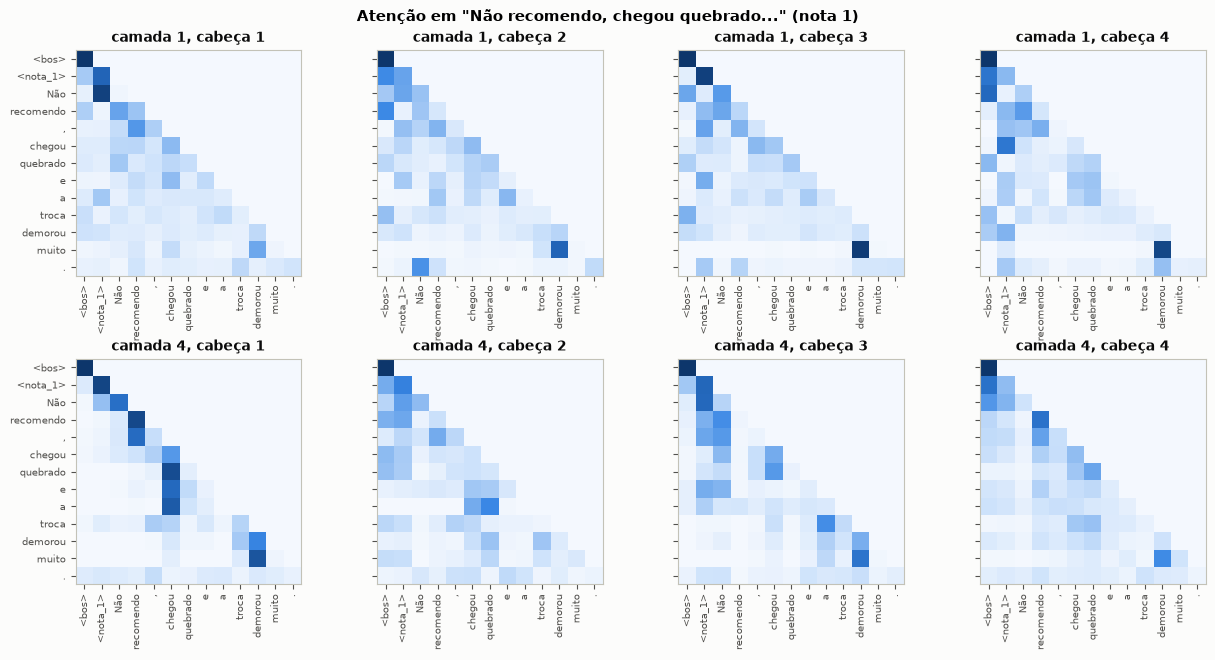

In [2]:
ids = encode_review(tokenizer, "Não recomendo, chegou quebrado e a troca demorou muito.", rating=1)
tokens = torch.tensor([ids[:-1]])  # a entrada do modelo, como no treino (sem o <eos>)
labels = [tokenizer.id_to_token(i).replace("▁", "") for i in ids[:-1]]
maps = attention_maps(tokens)[:, 0]  # (camadas, H, T, T)

layers_to_show = [0, config.n_layers - 1]
fig, axes = plt.subplots(len(layers_to_show), config.n_heads, figsize=(3.2 * config.n_heads, 6.6))
for row, layer in enumerate(layers_to_show):
    for head in range(config.n_heads):
        ax = axes[row, head]
        ax.imshow(maps[layer, head].numpy(), cmap=CMAP, vmin=0, vmax=1)
        ax.set_title(f"camada {layer + 1}, cabeça {head + 1}")
        ax.set_xticks(range(len(labels)), labels=labels, rotation=90, fontsize=7)
        ax.set_yticks(range(len(labels)), labels=labels if head == 0 else [], fontsize=7)
fig.suptitle('Atenção em "Não recomendo, chegou quebrado..." (nota 1)', fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "attention_maps.png")
plt.show()

## 2. Alguma cabeça olha para a nota?

Uma resenha não basta para concluir nada. A conta abaixo usa 1.000 resenhas da validação. Para cada
cabeça, ela mede o peso médio que as posições **a partir do 4º token de texto** dão ao token
`<nota_k>` (posição 1). Essas posições estão fora da janela do trigrama.

A referência é a atenção **uniforme**: uma cabeça que espalhasse o peso igualmente entre tudo o que
vê daria à nota, em média, o valor da linha "uniforme". Bem acima disso, a cabeça está procurando a
nota de propósito.

In [3]:
validation = pd.read_parquet(ROOT / "data" / "curated" / "validation.parquet").sample(
    1_000, random_state=0
)
loader = make_loader(
    ReviewDataset(validation, tokenizer, config.block_size), tokenizer, 64, False, 0
)
FIRST_POSITION = 5  # posição 5 = 4º token de texto (<bos>, <nota_k> e 3 tokens ficam de fora)
total = torch.zeros(config.n_layers, config.n_heads)
uniform_total, count = 0.0, 0
for x, y in loader:
    maps = attention_maps(x)  # (camadas, B, H, T, T)
    valid = (y != -100)[:, FIRST_POSITION:]  # só posições de texto, sem padding
    to_rating = maps[:, :, :, FIRST_POSITION:, 1]  # peso dado à posição 1 (a nota)
    total += (to_rating * valid[None, :, None, :]).sum(dim=(1, 3))
    positions = torch.arange(FIRST_POSITION, x.size(1)).float()
    uniform_total += float(((1 / (positions + 1))[None, :] * valid).sum())
    count += int(valid.sum())

to_rating = (total / count).numpy()
uniform = uniform_total / count
table = pd.DataFrame(
    to_rating.round(3),
    index=[f"camada {i + 1}" for i in range(config.n_layers)],
    columns=[f"cabeça {h + 1}" for h in range(config.n_heads)],
)
print(f"uniforme (referência): {uniform:.3f}")
table

uniforme (referência): 0.058


,cabeça 1,cabeça 2,cabeça 3,cabeça 4
camada 1,0.080,0.053,0.080,0.075
camada 2,0.063,0.040,0.089,0.114
camada 3,0.064,0.066,0.076,0.034
camada 4,0.050,0.052,0.054,0.062


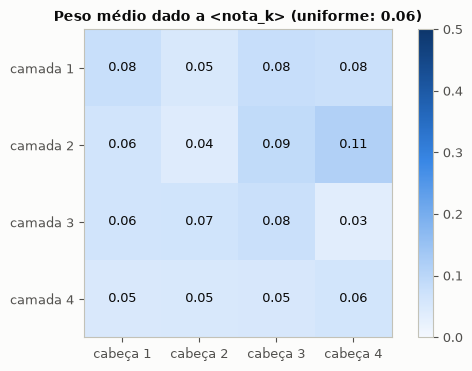

In [4]:
fig, ax = plt.subplots(figsize=(1.3 * config.n_heads + 1.5, 0.7 * config.n_layers + 1.2))
image = ax.imshow(to_rating, cmap=CMAP, vmin=0, vmax=max(0.5, float(to_rating.max())))
for (layer, head), value in np.ndenumerate(to_rating):
    ax.text(
        head,
        layer,
        f"{value:.2f}",
        ha="center",
        va="center",
        fontsize=9,
        color="#ffffff" if value > 0.6 * max(0.5, float(to_rating.max())) else "#0b0b0b",
    )
ax.set_xticks(range(config.n_heads), labels=[f"cabeça {h + 1}" for h in range(config.n_heads)])
ax.set_yticks(range(config.n_layers), labels=[f"camada {i + 1}" for i in range(config.n_layers)])
ax.set_title(f"Peso médio dado a <nota_k> (uniforme: {uniform:.2f})")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.savefig(FIG_DIR / "attention_to_rating.png")
plt.show()

## 3. Trocar a nota muda a previsão lá na frente?

O mesmo começo de resenha, quatro palavras de texto depois da nota, com `<nota_1>` e com `<nota_5>`.
Para o trigrama, as duas versões seriam **idênticas**: a nota já saiu da janela de duas palavras.
Se o Transformer prevê palavras diferentes, ele está usando a nota pela atenção.

In [5]:
def next_token_table(text: str, top: int = 8) -> pd.DataFrame:
    columns = {}
    for rating in (1, 5):
        ids = encode_review(tokenizer, text, rating=rating)[:-1]  # sem o <eos>: a frase continua
        with torch.no_grad():
            probabilities = torch.softmax(model(torch.tensor([ids]))[0, -1], dim=-1)
        best = probabilities.topk(top)
        columns[f"<nota_{rating}>"] = [
            f"{tokenizer.id_to_token(int(i))} ({p:.0%})"
            for p, i in zip(best.values, best.indices, strict=True)
        ]
    return pd.DataFrame(columns)


print('Começo: "O produto chegou e" -> próximo token')
next_token_table("O produto chegou e")

Começo: "O produto chegou e" -> próximo token


,<nota_1>,<nota_5>
0,▁não (12%),▁em (19%)
1,▁o (6%),▁bem (7%)
2,▁com (6%),▁muito (7%)
3,▁até (5%),▁antes (6%)
4,▁veio (4%),▁o (5%)
5,▁a (3%),▁no (5%)
6,▁ainda (3%),▁dentro (4%)
7,▁em (3%),▁com (3%)


In [6]:
print('Começo: "Comprei para minha mãe e ela" -> próximo token')
next_token_table("Comprei para minha mãe e ela")

Começo: "Comprei para minha mãe e ela" -> próximo token


,<nota_1>,<nota_5>
0,▁não (13%),▁adorou (21%)
1,▁é (7%),▁amou (17%)
2,▁está (6%),▁gostou (9%)
3,▁adorou (6%),▁é (6%)
4,▁amou (4%),▁está (3%)
5,▁gostou (3%),▁não (2%)
6,▁tem (3%),▁tem (2%)
7,▁veio (2%),▁são (2%)


## O que os três resultados dizem juntos

**Mapas (seção 1).** As cabeças fazem coisas diferentes. Há cabeças que olham sobretudo para o token
imediatamente anterior: a diagonal escura logo abaixo da principal, como na camada 4, cabeça 1. Há
cabeças que ligam palavras relacionadas mesmo a distância: "muito" olha para "demorou" nas cabeças
2 a 4 da camada 1. E há cabeças que voltam ao começo da resenha, a `<nota_1>` e o "Não", como na
camada 4, cabeça 3. Nenhuma delas foi programada para isso: o treino descobriu esses padrões porque
eles ajudam a prever o próximo token.

**Peso direto na nota (seção 2).** É modesto. A cabeça mais atenta à nota (camada 2, cabeça 4) dá a
ela cerca de 0,11 do peso, o dobro da atenção uniforme (0,06), mas nenhuma cabeça é "dedicada" à
nota. Isso **não** quer dizer que a nota é ignorada. A informação dela não precisa ser consultada
diretamente a cada palavra: nas primeiras camadas ela é copiada para a representação dos primeiros
tokens ("Não", "Recomendo"...), e a conexão residual leva essa informação adiante. Medir só a
atenção direta subestima o uso da nota.

**A prova direta (seção 3).** Com o mesmo começo de resenha, trocar `<nota_1>` por `<nota_5>` muda a
previsão **seis tokens depois** da nota: "Comprei para minha mãe e ela" continua com "não" na nota 1
e com "adorou"/"amou" na nota 5. Para o trigrama, as duas previsões seriam idênticas. É exatamente a
limitação que o charter apontou no baseline, e o mecanismo que a hipótese H2 (coerência) vai medir
na Etapa 3.